# Employee Churn Classification

Predict `left`: **0 = Stayed**, **1 = Left**. We compare four models using F1,
which balances precision and recall for employees who left.

- **Training:** tune models with five-fold stratified cross-validation.
- **Validation:** choose the prediction threshold and explain the selected model.
- **Test:** report final performance after the model and threshold are fixed.

The test set was inspected earlier in this project, so it is not a fresh holdout.
This project classifies recorded churn, not departures within a future time period.

## 1. Import libraries
Install `requirements.txt` before running the notebook. Run all cells from the project folder.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
)

## 2. Load and check the data
Keep the existing splits, which were created after removing exact duplicate rows.

In [2]:
train = pd.read_csv('data/train.csv')
val = pd.read_csv('data/val.csv')
test = pd.read_csv('data/test.csv')

# Use consistent column names in all three datasets.
for data in [train, val, test]:
    data.columns = data.columns.str.lower().str.strip()

data_summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Rows': [len(train), len(val), len(test)],
    'Missing values': [train.isna().sum().sum(), val.isna().sum().sum(), test.isna().sum().sum()],
    'Churn rate': [train['left'].mean(), val['left'].mean(), test['left'].mean()],
})
display(data_summary.round(4))

,Split,Rows,Missing values,Churn rate
0,Train,8393,0,0.1661
1,Validation,1799,0,0.1662
2,Test,1799,0,0.1656


## 3. Separate features and target
`X` contains the input features and `y` contains the churn label.

In [3]:
X_train = train.drop(columns='left')
y_train = train['left']

X_val = val.drop(columns='left')
y_val = val['left']

X_test = test.drop(columns='left')
y_test = test['left']

## 4. Define preprocessing
- Encode salary as low = 0, medium = 1, high = 2.
- One-hot encode departments.
- Scale numerical features for logistic regression and KNN, but not for trees.
- Keep binary features as 0/1.

Preprocessing stays **inside each pipeline**, so CV fits it on each training fold only.

In [4]:
numeric_columns = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company',
]
binary_columns = ['work_accident', 'promotion_last_5years']

scaled_preprocessor = ColumnTransformer([
    ('salary', OrdinalEncoder(categories=[['low', 'medium', 'high']],
                              handle_unknown='use_encoded_value', unknown_value=-1), ['salary']),
    ('department', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['departments']),
    ('numeric', StandardScaler(), numeric_columns),
    ('binary', 'passthrough', binary_columns),
])

tree_preprocessor = ColumnTransformer([
    ('salary', OrdinalEncoder(categories=[['low', 'medium', 'high']],
                              handle_unknown='use_encoded_value', unknown_value=-1), ['salary']),
    ('department', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['departments']),
    ('numeric', 'passthrough', numeric_columns),
    ('binary', 'passthrough', binary_columns),
])

## 5. Tuning
Use the same five stratified folds for every model. Stratification keeps similar churn
rates in each fold. Seed 42 makes the folds and stochastic models reproducible.

`scoring='f1'` chooses parameters using churn-class F1. `GridSearchCV` then fits
the best configuration on all training rows automatically. Two workers limit CPU usage.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Logistic regression
A simple linear baseline. `C` controls regularization; balanced class weights give
more weight to the minority class.

In [6]:
lr_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
lr_grid = {
    'model__C': [0.1, 1, 10],
    'model__class_weight': [None, 'balanced'],
}

lr_search = GridSearchCV(lr_pipeline, lr_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
lr_search.fit(X_train, y_train)
print('Best parameters:', lr_search.best_params_)
print('Mean CV F1:', round(lr_search.best_score_, 4))

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Mean CV F1: 0.5456


### K-nearest neighbors
Try different numbers of neighbors and either equal or distance-based voting.

In [7]:
knn_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', KNeighborsClassifier()),
])
knn_grid = {
    'model__n_neighbors': [3, 5, 7, 9],
    'model__weights': ['uniform', 'distance'],
}

knn_search = GridSearchCV(knn_pipeline, knn_grid, scoring='f1', cv=cv,
                          n_jobs=2, pre_dispatch=2, error_score='raise')
knn_search.fit(X_train, y_train)
print('Best parameters:', knn_search.best_params_)
print('Mean CV F1:', round(knn_search.best_score_, 4))

Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Mean CV F1: 0.8712


### Random Forest
Tune the number of trees, maximum depth, and minimum samples needed to split a node.

In [8]:
rf_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1)),
])
rf_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5],
}

rf_search = GridSearchCV(rf_pipeline, rf_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
rf_search.fit(X_train, y_train)
print('Best parameters:', rf_search.best_params_)
print('Mean CV F1:', round(rf_search.best_score_, 4))

Best parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Mean CV F1: 0.9451


### Gradient Boosting
Tune the number of trees, learning rate, and tree depth.

In [ ]:
gb_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', GradientBoostingClassifier(random_state=42)),
])
gb_grid = {
    'model__n_estimators': [100, 150],
    'model__learning_rate': [0.01, 0.1, 0.001],
    'model__max_depth': [3, 5],
}

gb_search = GridSearchCV(gb_pipeline, gb_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
gb_search.fit(X_train, y_train)
print('Best parameters:', gb_search.best_params_)
print('Mean CV F1:', round(gb_search.best_score_, 4))

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 150}
Mean CV F1: 0.9442


## 6. Compare CV results and select a model
Choose the highest mean CV F1, not the highest test score. The standard deviation
shows variation across folds; it is not a confidence interval.

In [10]:
searches = {
    'Logistic Regression': lr_search,
    'KNN': knn_search,
    'Random Forest': rf_search,
    'Gradient Boosting': gb_search,
}

cv_rows = []
for name, search in searches.items():
    best_index = search.best_index_
    cv_rows.append({
        'Model': name,
        'Mean CV F1': search.best_score_,
        'CV F1 std': search.cv_results_['std_test_score'][best_index],
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ['Mean CV F1', 'Model'], ascending=[False, True]
).reset_index(drop=True)
display(cv_results.round(4))

best_name = cv_results.loc[0, 'Model']
best_model = searches[best_name].best_estimator_
print('Selected model:', best_name)
print('Selected parameters:', searches[best_name].best_params_)

,Model,Mean CV F1,CV F1 std
0,Random Forest,0.9451,0.0112
1,Gradient Boosting,0.9442,0.0088
2,KNN,0.8712,0.0103
3,Logistic Regression,0.5456,0.0066


Selected model: Random Forest
Selected parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}


**Conclusion:** Random Forest has the highest mean CV F1 (0.9451), closely followed
by Gradient Boosting (0.9442). This small difference does not prove that one is
significantly better. We keep Random Forest according to our selection rule.

## 7. Choose a threshold using validation data
A threshold decides when a probability becomes a Left prediction. Try each unique
validation probability and keep the threshold with the highest F1. Start at 0.5
so it stays selected if no candidate improves F1. Do not refit the model afterward.

In [11]:
val_probabilities = best_model.predict_proba(X_val)[:, 1]

best_threshold = 0.5
best_val_f1 = f1_score(y_val, val_probabilities >= best_threshold)

for threshold in np.unique(val_probabilities):
    val_predictions = (val_probabilities >= threshold).astype(int)
    score = f1_score(y_val, val_predictions, zero_division=0)
    if score > best_val_f1:
        best_val_f1 = score
        best_threshold = threshold

print('Selected threshold:', round(best_threshold, 4))

Selected threshold: 0.4983


In [12]:
# Reuse this short function for validation and test results.
def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'Average precision': average_precision_score(y_true, probabilities),
    }

validation_results = pd.DataFrame([
    evaluate_model(y_val, val_probabilities, 0.5),
    evaluate_model(y_val, val_probabilities, best_threshold),
], index=['Default threshold', 'Selected threshold'])
display(validation_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Default threshold,0.9867,0.9964,0.9231,0.9583,0.9851,0.968
Selected threshold,0.9872,0.9964,0.9264,0.9601,0.9851,0.968


**Conclusion:** The selected threshold is about 0.4983. Validation F1 increases
slightly, from 0.9583 to 0.9601. These are development scores because validation
data was used to choose the threshold. ROC-AUC and average precision do not change
with the threshold because they measure probability ranking.

## 8. Explain the selected model
Permutation importance shuffles one original feature at a time and measures how
much F1 decreases at our selected threshold. Repeat ten times to check variation.
Larger decreases mean the model relies more on that feature. This does not show causation,
and correlated features can share importance. Use this for explanation, not further tuning.

,Feature,Mean F1 decrease,Std
0,satisfaction_level,0.6245,0.0186
1,last_evaluation,0.3598,0.0202
2,number_project,0.3516,0.0169
3,average_montly_hours,0.3471,0.0123
4,time_spend_company,0.2912,0.0173
7,departments,0.0015,0.0015
5,work_accident,0.0003,0.0007
6,promotion_last_5years,0.0002,0.0005
8,salary,0.0002,0.0005


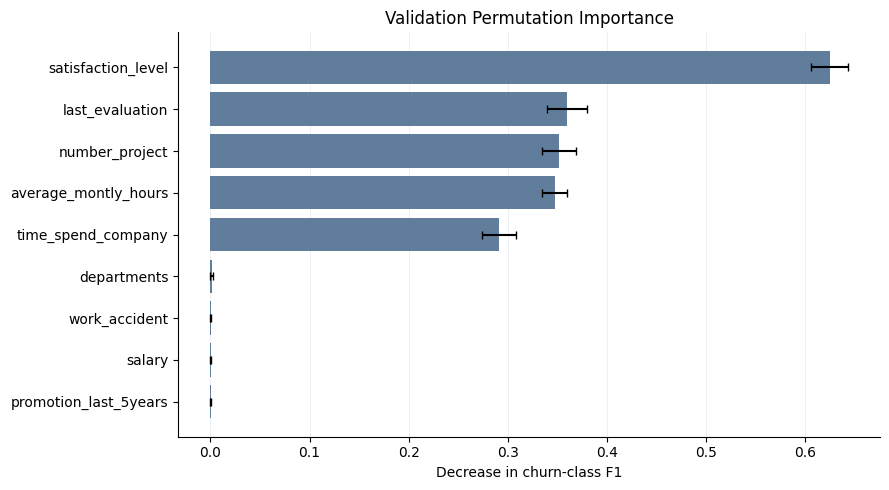

In [13]:
def threshold_f1(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= best_threshold).astype(int)
    return f1_score(y, predictions, zero_division=0)

importance = permutation_importance(
    best_model, X_val, y_val, scoring=threshold_f1,
    n_repeats=10, random_state=42,
)

importance_results = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean F1 decrease': importance.importances_mean,
    'Std': importance.importances_std,
}).sort_values('Mean F1 decrease', ascending=False)
display(importance_results.round(4))

plot_data = importance_results.sort_values('Mean F1 decrease')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data['Feature'], plot_data['Mean F1 decrease'],
        xerr=plot_data['Std'], color='#607D9C', capsize=3)
ax.set_title('Validation Permutation Importance')
ax.set_xlabel('Decrease in churn-class F1')
ax.set_axisbelow(True)
ax.grid(axis='x', color='#E9EDF2', linewidth=0.6)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Conclusion:** Satisfaction, last evaluation, and project count have the largest
importance scores. These connect to the satisfaction and workload patterns explored
in the EDA. Salary has little additional importance in this model, but this does
not mean salary is unrelated to churn or that any feature causes departures.

## 9. Final test evaluation
Compare all four CV-tuned models at threshold 0.5, plus an always-Stayed baseline.
Show the CV-selected model separately at its validation-selected threshold.
The selected model and settings stay fixed: test scores are for reporting, not selection.
The baseline shows why high accuracy alone can be misleading.

In [14]:
baseline = DummyClassifier(strategy='constant', constant=0)
baseline.fit(X_train, y_train)

# Compare each model's best CV configuration using the same threshold.
test_rows = []
for name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]
    row = {'Model': name, 'Decision rule': 'Default', 'Threshold': 0.5}
    row.update(evaluate_model(y_test, probabilities, 0.5))
    test_rows.append(row)

baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
row = {'Model': 'Always Stayed', 'Decision rule': 'Baseline', 'Threshold': 0.5}
row.update(evaluate_model(y_test, baseline_probabilities, 0.5))
test_rows.append(row)

# Report the finalized model separately at its validation-selected threshold.
test_probabilities = best_model.predict_proba(X_test)[:, 1]
row = {'Model': best_name, 'Decision rule': 'Validation-selected', 'Threshold': best_threshold}
row.update(evaluate_model(y_test, test_probabilities, best_threshold))
test_rows.append(row)

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

# Save only the final results table. No model files or JSON metadata are written.
Path('results').mkdir(exist_ok=True)
test_results.to_csv('results/test_metrics.csv', index=False)

,Model,Decision rule,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
0,Logistic Regression,Default,0.5000,0.7765,0.4130,0.8289,0.5513,0.8453,0.3843
1,KNN,Default,0.5000,0.9566,0.8374,0.9161,0.8750,0.9532,0.8531
2,Random Forest,Default,0.5000,0.9828,0.9785,0.9161,0.9463,0.9748,0.9611
3,Gradient Boosting,Default,0.5000,0.9839,0.9654,0.9362,0.9506,0.9825,0.9675
4,Always Stayed,Baseline,0.5000,0.8344,0.0000,0.0000,0.0000,0.5000,0.1656
5,Random Forest,Validation-selected,0.4983,0.9839,0.9786,0.9228,0.9499,0.9748,0.9611


**Final conclusion:** Random Forest achieves test F1 of 0.9499, precision of 0.9786,
and recall of 0.9228. The always-Stayed baseline achieves 83.4% accuracy but misses
every departure. Gradient Boosting has a slightly higher test F1 (0.9506), but
Random Forest remains selected because model selection used CV, not test scores.
Satisfaction and workload-related features are important for prediction.